# C09 · Tăng trưởng thương mại Việt Nam theo đối tác

- **Module / task:** M7 / T23. **Người làm:** Nguyễn Ngọc Khánh Vân. **CHECK:** Ngọc — chờ rà soát độc lập.
- **Câu hỏi:** Tăng trưởng thương mại với các đối tác lớn thay đổi thế nào qua từng năm?
- **Nhiệm vụ:** So sánh tăng trưởng kim ngạch giữa các đối tác và các năm; xác định năm có nhiều đối tác suy giảm nhất. Tiêu đề chính nêu kết luận có số liệu, được tính tự động từ ma trận tăng trưởng.
- **Dạng và lý do:** Heatmap đối tác × năm; vị trí cố định giúp đối chiếu từng hàng/cột, màu phân kỳ làm nổi tăng/giảm quanh 0.
- **Nguồn:** `data/clean/partner_year.csv`, CEPII BACI HS2002 V202601, USD danh nghĩa. Hai chiều Export và Import được cộng thành tổng thương mại.
- **Phạm vi:** Top 20 đối tác theo tổng kim ngạch quan sát trong 2005–2024; không lọc theo hạng riêng năm cuối. Lọc ISO3 hợp lệ bằng House Style, loại mã tổng hợp và Việt Nam.
- **Tăng trưởng:** `(kim_ngach_t / kim_ngach_t_1 − 1) × 100`. Hiển thị 2006–2024 do không có số 2004. Chỉ tính khi đủ cả hai chiều ở hai năm liên tiếp và năm trước > 0. Thiếu dữ liệu không được điền thành 0; không lấy năm gần nhất thay năm liền trước.
- **Sắp xếp (seriation):** Giảm dần tổng kim ngạch 2005–2024; hòa hạng dùng ISO3. Cách này giữ thứ tự quy mô dễ tra cứu, không ngụ ý các hàng liền nhau cùng cụm M6.
- **Màu và thang đo:** Dùng `DIVERGING_CMAP`, `diverging_norm` của House Style; đỏ giảm, xanh tăng, tâm 0. Thang màu cố định −100% đến +100%; giá trị vượt ngưỡng bão hòa màu nhưng nhãn và CSV giữ giá trị thật. Ô xám là không tính được, không phải tăng trưởng 0%.
- **Tham số:** Năm, số đối tác, chiều thương mại, ngưỡng màu và nhãn số được khai báo tại ô chạy. Tên quốc gia hiển thị tiếng Việt và ISO3 để dễ đối chiếu.


In [1]:
# T23 / C09 — HÀM CHUẨN BỊ DỮ LIỆU
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT_C09 = next(p for p in (Path.cwd(), *Path.cwd().parents)
                if (p/'notebooks/house_style/house_style.py').is_file())
if str(ROOT_C09) not in sys.path:
    sys.path.insert(0, str(ROOT_C09))
from notebooks.house_style.house_style import (
    apply_style, DIVERGING_CMAP, MISSING_COLOR, SOURCE, SUBTITLE,
    diverging_norm, format_number, is_partner_code,
)

NAMES_C09 = {
    'CHN': 'Trung Quốc', 'USA': 'Hoa Kỳ', 'KOR': 'Hàn Quốc', 'JPN': 'Nhật Bản',
    'THA': 'Thái Lan', 'HKG': 'Hồng Kông (Trung Quốc)', 'DEU': 'Đức',
    'SGP': 'Singapore', 'MYS': 'Malaysia', 'IND': 'Ấn Độ', 'AUS': 'Úc',
    'IDN': 'Indonesia', 'GBR': 'Vương quốc Anh', 'FRA': 'Pháp',
    'NLD': 'Hà Lan', 'CAN': 'Canada', 'ITA': 'Ý', 'MEX': 'Mexico',
    'ARE': 'Các Tiểu vương quốc Ả Rập TN', 'PHL': 'Philippines',
}

def prep_c09(raw, start_year=2005, end_year=2024, top_n=20, flow='Total'):
    """Trả về ma trận tăng trưởng, bảng kiểm toán dài và thứ hạng đối tác."""
    if not (isinstance(start_year, int) and isinstance(end_year, int) and start_year < end_year):
        raise ValueError('Khoảng năm phải gồm ít nhất hai năm nguyên liên tiếp.')
    if not isinstance(top_n, int) or top_n < 1 or flow not in ('Total', 'Export', 'Import'):
        raise ValueError('Kiểm tra số đối tác và chiều thương mại.')
    required = {'year', 'trade_flow', 'partner_code', 'partner_iso3', 'partner_name', 'trade_usd'}
    if not required <= set(raw):
        raise ValueError(f'Thiếu cột: {sorted(required-set(raw))}')
    d = raw.copy(deep=True)
    year = pd.to_numeric(d.year, errors='raise')
    if not (np.isfinite(year).all() and year.mod(1).eq(0).all()):
        raise ValueError('Năm bị thiếu hoặc không nguyên.')
    d['year'] = year.astype(int)
    for col in ('partner_code', 'partner_iso3', 'trade_flow'):
        d[col] = d[col].fillna('').astype(str).str.strip()
    d = d.loc[d.year.between(start_year, end_year)
              & d.partner_iso3.map(is_partner_code) & d.partner_iso3.ne('VNM')
              & ~d.partner_code.str.lstrip('0').isin(('', '999'))].copy()
    if not d.trade_flow.isin(('Export', 'Import')).all():
        raise ValueError('Có chiều thương mại không hợp lệ.')
    if d.duplicated(['year', 'trade_flow', 'partner_code']).any():
        raise ValueError('Trùng khóa năm × chiều × mã đối tác.')
    if d.groupby('partner_code').partner_iso3.nunique().gt(1).any():
        raise ValueError('Một mã đối tác ứng với nhiều ISO3.')
    # Mã lịch sử có thể đổi giữa các năm; cấm hai mã cùng ISO3 trong cùng năm/chiều.
    if d.duplicated(['year', 'trade_flow', 'partner_iso3']).any():
        raise ValueError('Nhiều mã ứng cùng ISO3 trong một năm/chiều; cần rà soát trước khi gộp.')
    d['trade_usd'] = pd.to_numeric(d.trade_usd, errors='raise')
    if not (np.isfinite(d.trade_usd).all() and d.trade_usd.ge(0).all()):
        raise ValueError('Kim ngạch thiếu, âm hoặc không hữu hạn.')
    flows = ['Export', 'Import'] if flow == 'Total' else [flow]
    d = d.loc[d.trade_flow.isin(flows)]
    ranking = (d.groupby('partner_iso3', as_index=False)
               .agg(period_trade_usd=('trade_usd', 'sum'), partner_name=('partner_name', 'first'))
               .sort_values(['period_trade_usd', 'partner_iso3'], ascending=[False, True]))
    ranking = ranking.loc[ranking.period_trade_usd.gt(0)].head(top_n).reset_index(drop=True)
    if ranking.empty:
        raise ValueError('Không có đối tác có kim ngạch dương trong phạm vi chọn.')
    ranking['rank'] = np.arange(1, len(ranking)+1)
    years = list(range(start_year, end_year+1))
    index = pd.MultiIndex.from_product([ranking.partner_iso3, years], names=['partner_iso3', 'year'])
    panel = (d.pivot(index=['partner_iso3', 'year'], columns='trade_flow', values='trade_usd')
             .reindex(index=index, columns=flows))
    complete = panel.notna().all(axis=1)
    total = panel.sum(axis=1, min_count=len(flows))
    audit = pd.DataFrame({'trade_usd': total, 'complete': complete})
    audit['previous_trade_usd'] = audit.groupby(level=0).trade_usd.shift(1)
    audit['previous_complete'] = audit.groupby(level=0).complete.shift(1).eq(True)
    audit['status'] = 'ok'
    audit.loc[~audit.previous_complete, 'status'] = 'missing_previous'
    audit.loc[audit.previous_trade_usd.eq(0), 'status'] = 'zero_previous'
    audit.loc[~audit.complete, 'status'] = 'missing_current'
    audit.loc[index.get_level_values('year') == start_year, 'status'] = 'baseline_no_previous_year'
    usable = audit.status.eq('ok')
    audit['growth_pct'] = np.nan
    audit.loc[usable, 'growth_pct'] = (audit.loc[usable, 'trade_usd'] /
                                     audit.loc[usable, 'previous_trade_usd'] - 1) * 100
    if not np.isfinite(audit.loc[usable, 'growth_pct']).all():
        raise ValueError('Tăng trưởng không hữu hạn.')
    matrix = (audit.growth_pct.unstack('year').reindex(ranking.partner_iso3)
              .loc[:, range(start_year+1, end_year+1)])
    audit = audit.reset_index().merge(ranking, on='partner_iso3', how='left', validate='many_to_one')
    return matrix, audit, ranking


In [2]:
# T23 / C09 — HÀM VẼ, HOUSE STYLE VÀ XUẤT HÌNH
from matplotlib.figure import Figure
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from matplotlib import rc_context

def plot_c09(matrix, ranking, start_year, end_year, flow='Total', color_limit=100, annotate=True):
    if not np.isfinite(color_limit) or color_limit <= 0:
        raise ValueError('Ngưỡng màu phải dương và hữu hạn.')
    if matrix.shape[0] == 0 or matrix.shape[1] == 0 or not np.isfinite(matrix.to_numpy()).any():
        raise ValueError('Không có tăng trưởng hợp lệ để vẽ.')
    values = matrix.to_numpy(dtype=float)
    low, high = np.nanmin(values), np.nanmax(values)
    extension = ('both' if low < -color_limit and high > color_limit else
                 'min' if low < -color_limit else 'max' if high > color_limit else 'neither')
    flow_label = {'Total': 'Tổng xuất khẩu + nhập khẩu', 'Export': 'Xuất khẩu', 'Import': 'Nhập khẩu'}[flow]
    # Action title được tính từ năm có nhiều đối tác suy giảm nhất, không nhập cứng kết luận.
    negative_counts = matrix.lt(0).sum(axis=0)
    worst = int(negative_counts.idxmax())
    observed = int(matrix[worst].notna().sum())
    action = (f'Năm {worst}: {int(negative_counts[worst])}/{observed} đối tác giảm kim ngạch, '
              f'nhiều nhất giai đoạn {int(matrix.columns.min())}–{int(matrix.columns.max())}')
    with apply_style():
        fig = Figure(figsize=(15, max(9.5, 4.7 + len(matrix)*0.27)))
        ax = fig.add_axes((.235, .245, .71, .535))
        cmap = DIVERGING_CMAP.with_extremes(bad=MISSING_COLOR)
        norm = diverging_norm(-color_limit, color_limit)
        im = ax.imshow(np.ma.masked_invalid(values), cmap=cmap, norm=norm,
                       aspect='auto', interpolation='nearest')
        ax.set_xticks(np.arange(len(matrix.columns)), [str(y) for y in matrix.columns], fontsize=9)
        labels = [f'{NAMES_C09.get(iso, ranking.set_index("partner_iso3").loc[iso,"partner_name"])} · {iso}'
                  for iso in matrix.index]
        ax.set_yticks(np.arange(len(matrix)), labels, fontsize=9)
        ax.set_xlabel('Năm · so với năm liền trước', labelpad=10)
        ax.set_xticks(np.arange(-.5, len(matrix.columns), 1), minor=True)
        ax.set_yticks(np.arange(-.5, len(matrix), 1), minor=True)
        ax.grid(which='minor', color='white', linewidth=.8)
        ax.tick_params(which='both', length=0)
        for spine in ax.spines.values():
            spine.set_visible(False)
        if annotate:
            for (i, j), value in np.ndenumerate(values):
                if np.isfinite(value):
                    rgb = cmap(norm(value))[:3]
                    luminance = sum(w*c for w,c in zip((.2126,.7152,.0722), rgb))
                    ax.text(j, i, format_number(value, 0, signed=True), ha='center', va='center',
                            fontsize=7.4, color='white' if luminance < .46 else '#222222')
                else:
                    ax.text(j, i, '—', ha='center', va='center', fontsize=9, color='#555555')
        cax = fig.add_axes((.31, .15, .49, .019))
        bar = fig.colorbar(im, cax=cax, orientation='horizontal', extend=extension)
        bar.set_ticks([-color_limit, -color_limit/2, 0, color_limit/2, color_limit])
        bar.ax.xaxis.set_major_formatter(FuncFormatter(lambda x,_: format_number(x,0,signed=True)+'%'))
        bar.ax.tick_params(labelsize=9)
        bar.set_label('Giảm ← Tăng trưởng kim ngạch so với năm trước (%) → Tăng', fontsize=10)
        ax.legend(handles=[Patch(facecolor=MISSING_COLOR, label='— Không tính được do thiếu dữ liệu hoặc năm trước bằng 0')],
                  loc='upper center', bbox_to_anchor=(.5, -.085), frameon=False, fontsize=9)
        fig.suptitle(action, y=.956, va='center', fontsize=19)
        fig.text(.5, .919, f'{flow_label} · Top {len(matrix)} đối tác theo kim ngạch cộng dồn {start_year}–{end_year}',
                 **(SUBTITLE | {'va':'center'}))
        fig.text(.5, .865, 'So sánh tăng trưởng từng năm để xác định các đợt suy giảm trên nhiều đối tác',
                 ha='center', fontsize=11, color='#555555')
        clipped = int((np.abs(values[np.isfinite(values)]) > color_limit).sum())
        missing = int(np.isnan(values).sum())
        fig.text(.5, .065,
                 f'Màu giới hạn ±{format_number(color_limit,0)}%; {clipped} ô vượt ngưỡng giữ nhãn thật. '
                 f'Nhãn làm tròn số nguyên; CSV giữ đủ độ chính xác. {missing} ô không tính được.', **SOURCE)
        fig.text(.5, .039,
                 f'Hàng xếp theo kim ngạch cộng dồn giảm dần; không tính tăng trưởng {start_year} vì thiếu năm {start_year-1}.', **SOURCE)
        fig.text(.5, .013, 'Nguồn: CEPII BACI HS2002 V202601 · partner_year.csv · USD danh nghĩa', **SOURCE)
    return fig, ax, action

def export_c09(fig, out):
    out.mkdir(parents=True, exist_ok=True)
    with apply_style(), rc_context({'svg.fonttype':'path'}):
        for extension in ('png', 'svg'):
            fig.savefig(out/f'C09_heatmap.{extension}', dpi=300, bbox_inches='tight', facecolor='white')
    return out/'C09_heatmap.png'


Năm 2009: 17/20 đối tác giảm kim ngạch, nhiều nhất giai đoạn 2006–2024
Kiểm tra đạt: 20 đối tác × 19 năm; tâm màu 0; giữ nguyên số liệu thật.
Ô không tính được trong hình:
Ô vượt ngưỡng màu:


,partner_iso3,year,status
379,ARE,2024,missing_current


,partner_iso3,year,growth_pct
119,HKG,2024,107.73
159,SGP,2024,111.21
372,ARE,2017,197.58


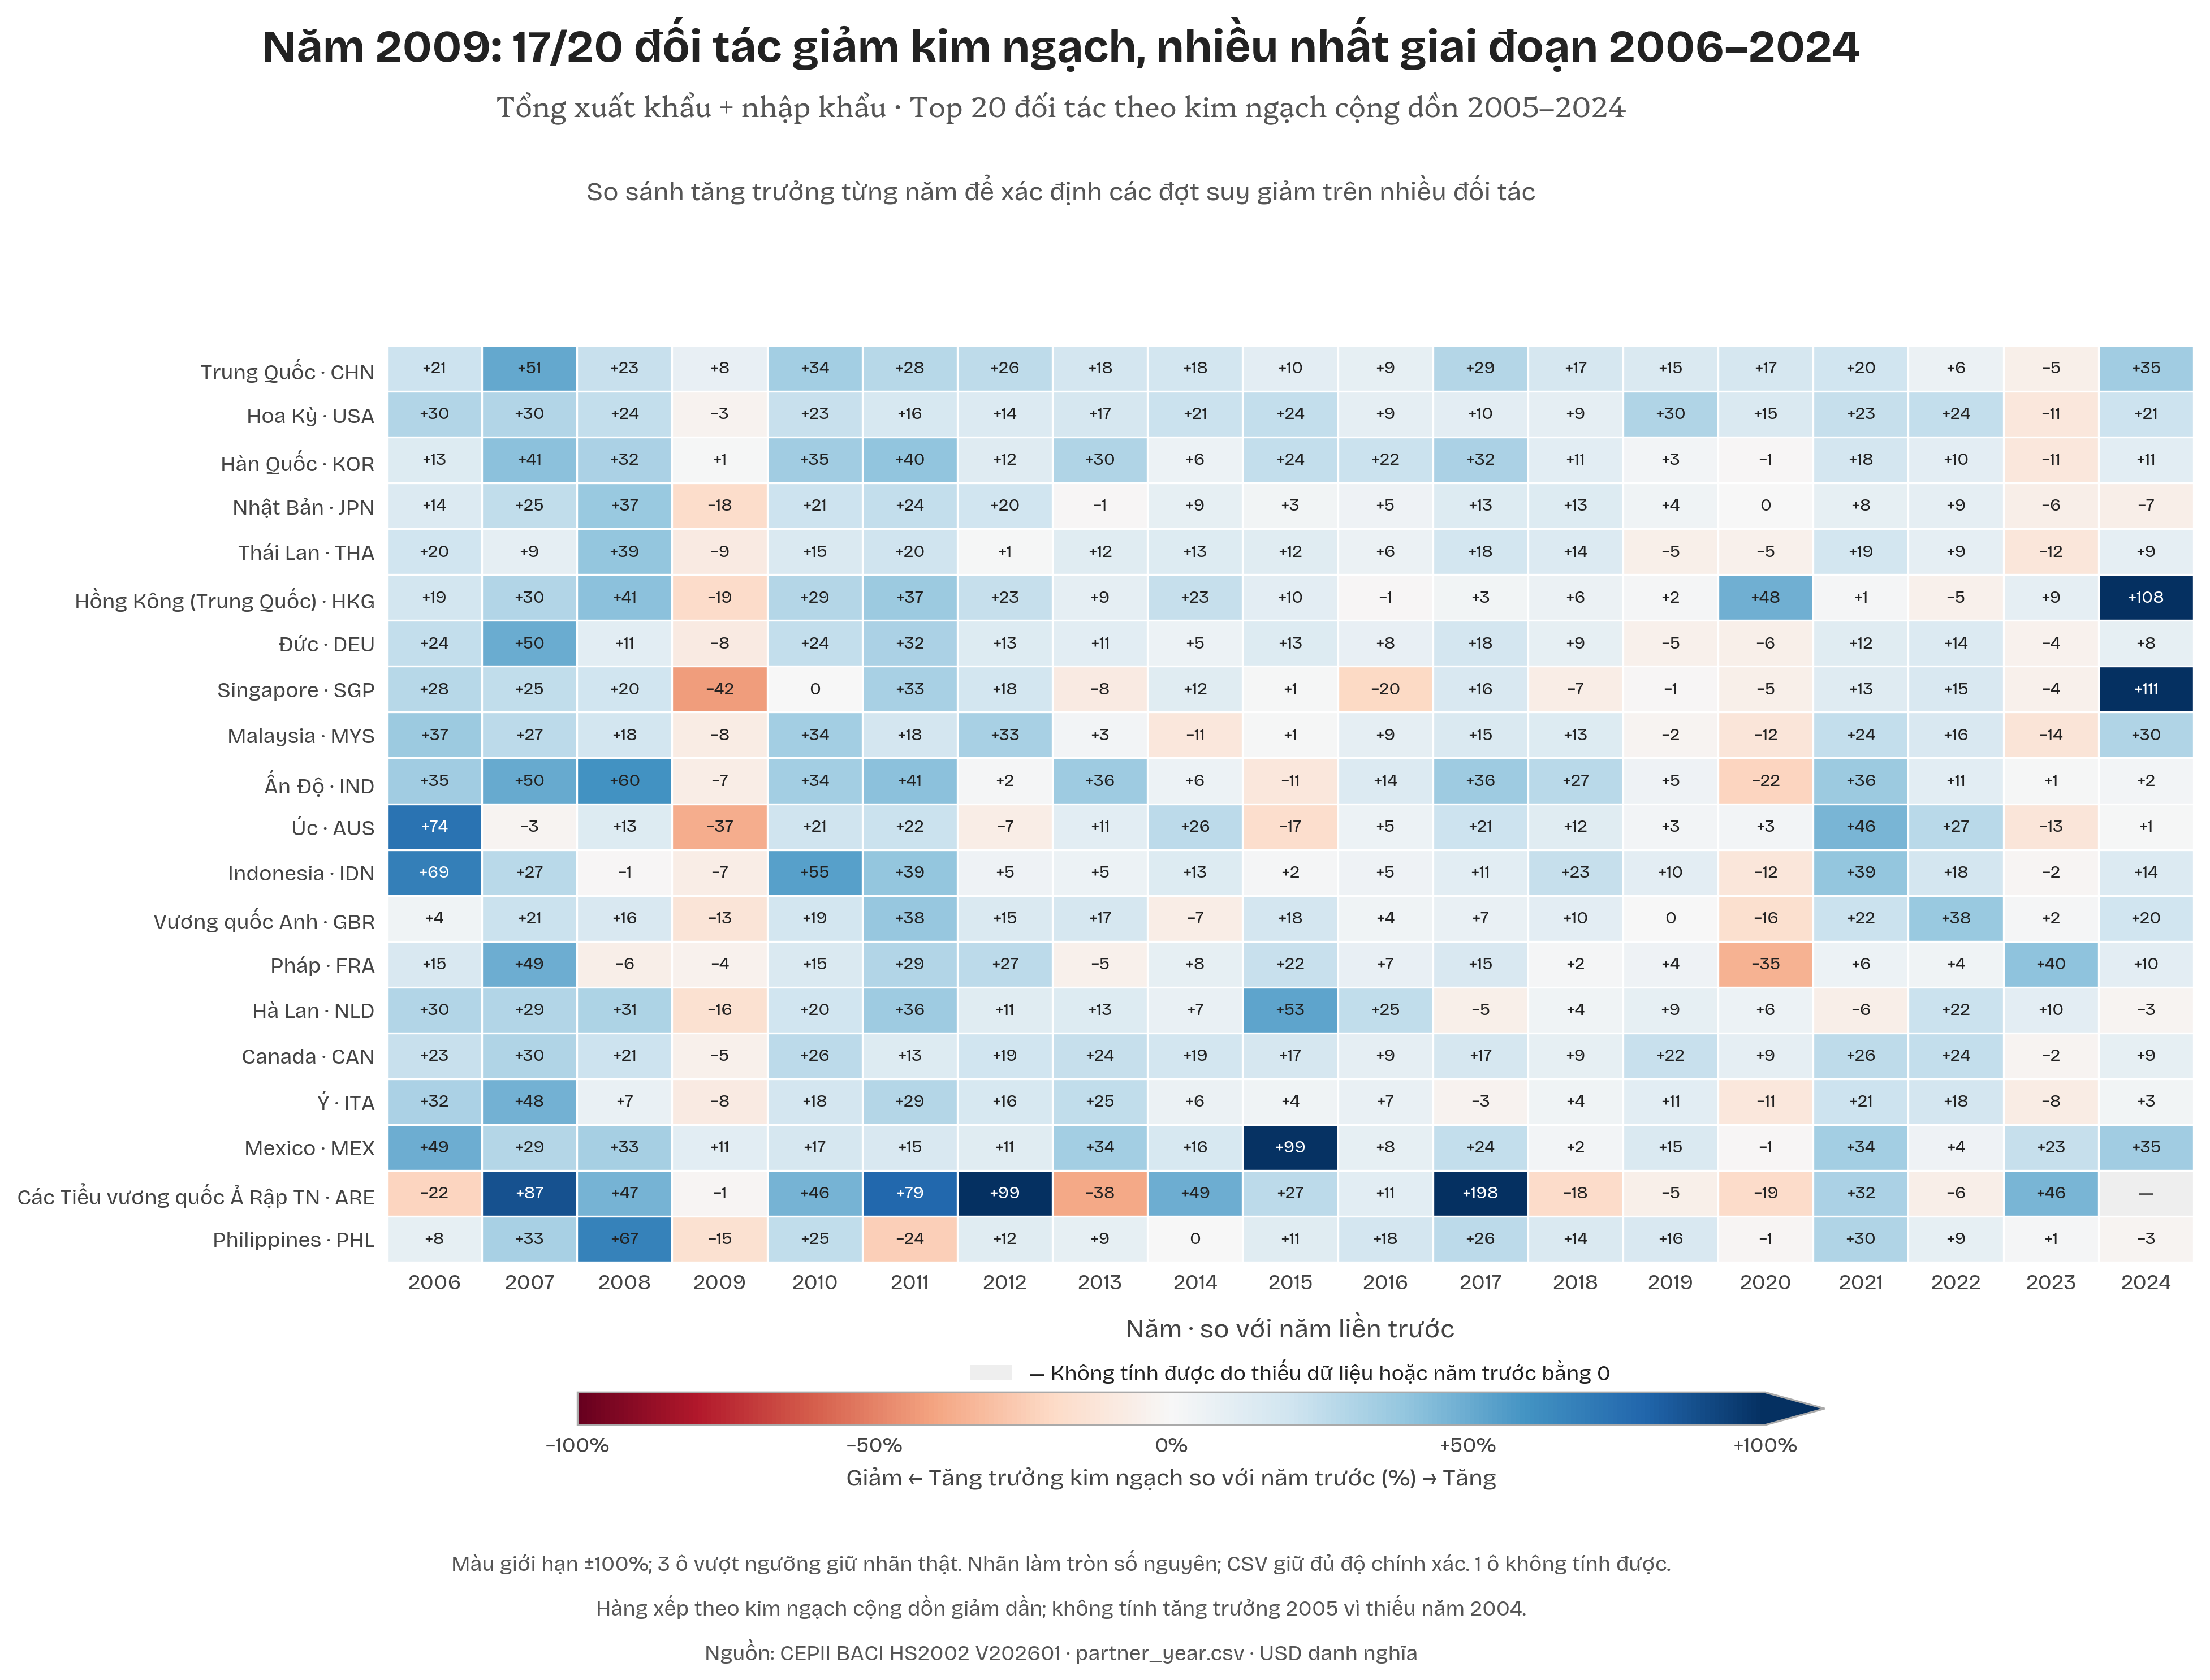

In [3]:
# T23 / C09 — THAM SỐ → GỌI HÀM → KIỂM TRA → LƯU HÌNH
START_YEAR_C09 = 2005
END_YEAR_C09 = 2024
TOP_N_C09 = 20
FLOW_C09 = 'Total'  # 'Total', 'Export' hoặc 'Import'
COLOR_LIMIT_C09 = 100
ANNOTATE_C09 = True
OUT_C09 = ROOT_C09/'outputs/multivariate'

raw_c09 = pd.read_csv(ROOT_C09/'data/clean/partner_year.csv',
                     dtype={'partner_code':str, 'partner_iso3':str}, encoding='utf-8-sig')
matrix_c09, audit_c09, ranking_c09 = prep_c09(raw_c09, START_YEAR_C09, END_YEAR_C09, TOP_N_C09, FLOW_C09)
fig_c09, ax_c09, action_c09 = plot_c09(matrix_c09, ranking_c09, START_YEAR_C09, END_YEAR_C09,
                                     FLOW_C09, COLOR_LIMIT_C09, ANNOTATE_C09)
assert matrix_c09.shape == (TOP_N_C09, END_YEAR_C09-START_YEAR_C09)
assert matrix_c09.index.is_unique and matrix_c09.columns.is_unique
assert set(matrix_c09.index).isdisjoint({'S19','WLD','VNM'})
valid_c09 = audit_c09.status.eq('ok')
np.testing.assert_allclose(audit_c09.loc[valid_c09,'growth_pct'],
    (audit_c09.loc[valid_c09,'trade_usd']/audit_c09.loc[valid_c09,'previous_trade_usd']-1)*100)
assert audit_c09.loc[~valid_c09,'growth_pct'].isna().all()
np.testing.assert_allclose(ax_c09.images[0].get_array().filled(np.nan), matrix_c09.to_numpy(), equal_nan=True)
assert ax_c09.images[0].norm(0) == .5
png_c09 = export_c09(fig_c09, OUT_C09)
audit_c09['color_clipped'] = audit_c09.growth_pct.abs().gt(COLOR_LIMIT_C09)
audit_c09['flow_scope'] = FLOW_C09
audit_c09.to_csv(OUT_C09/'C09_growth_audit.csv',index=False,encoding='utf-8-sig')
ranking_c09.to_csv(OUT_C09/'C09_partner_ranking.csv',index=False,encoding='utf-8-sig')
print(action_c09)
print(f'Kiểm tra đạt: {matrix_c09.shape[0]} đối tác × {matrix_c09.shape[1]} năm; tâm màu 0; giữ nguyên số liệu thật.')
print('Ô không tính được trong hình:')
display(audit_c09.loc[audit_c09.year.gt(START_YEAR_C09) & ~valid_c09,
                    ['partner_iso3','year','status']])
print('Ô vượt ngưỡng màu:')
display(audit_c09.loc[audit_c09.color_clipped,['partner_iso3','year','growth_pct']].round(2))
display(Image(data=png_c09.read_bytes(), width=1200))


## Nhận xét và giới hạn

Kết luận dưới đây ứng với tham số mặc định: Top 20 đối tác theo tổng thương mại hai chiều 2005–2024. Nếu đổi tham số, cần đọc lại kết quả và cập nhật nhận xét.

- **Năm 2009 có 17/20 đối tác giảm tổng kim ngạch**, nhiều nhất trong các năm hiển thị. Năm 2020 có 13/20 và năm 2023 có 12/20 đối tác giảm.
- **Hồng Kông và Singapore tăng lần lượt khoảng 107.7% và 111.2% năm 2024**. UAE tăng khoảng 197.6% năm 2017. Đây là ba ô vượt ngưỡng màu +100%; số không bị cắt trong dữ liệu.
- **UAE năm 2024 không có dòng dữ liệu trong bảng nguồn**, nên ô tương ứng không tính được. Không diễn giải thành kim ngạch bằng 0 hoặc giảm 100%.

- Các cột đỏ cùng năm cho thấy nhiều đối tác cùng giảm kim ngạch; đây là sự đồng thời trong số liệu, không chứng minh một nguyên nhân chung.
- Đọc kim ngạch giảm ở từng ô so với chính đối tác đó năm trước. Màu không biểu thị quy mô hay mức phụ thuộc, và không phải CAGR của cả giai đoạn.
- Phạm vi chỉ gồm Top 20; kim ngạch dùng USD danh nghĩa, chưa điều chỉnh lạm phát. Thứ hạng dựa trên toàn giai đoạn nên không đại diện cho hạng riêng năm 2024.
- Ô thiếu hoặc năm trước bằng 0 không thể tính tăng trưởng theo công thức này. Không suy rằng quốc gia đã ngừng giao thương chỉ vì ô xám.
- Các giá trị vượt ±100% dùng màu bão hòa để giữ khả năng đọc phần còn lại; nhãn vẫn là giá trị thật làm tròn, hai bảng CSV cho phép đối chiếu chính xác.

## Bàn giao và sử dụng AI

- Notebook này giữ cấu trúc: mô tả → hàm dữ liệu → hàm vẽ → tham số/kiểm tra/xuất → nhận xét.
- Đầu ra: `outputs/multivariate/C09_heatmap.png`, `.svg`, `C09_growth_audit.csv`, `C09_partner_ranking.csv`.
- Gộp vào `04_multivariate.ipynb` ở bước tổng hợp M7; không sửa notebook tổng trong task này.
- AI hỗ trợ xây dựng code, kiểm tra xử lý thiếu và bố cục. Vân cần đọc, xác nhận quyết định; Ngọc CHECK độc lập trước khi merge. Chưa coi là đã được người CHECK duyệt.
